# Formas canônicas

Este notebook obtém representações em espaço de estados do sistema nas formas canônicas controlável, observável e de Jordan, cada uma a partir de uma função de transferência.

Como o sistema é MIMO, com 3 entradas e 9 saídas, ele tem 27 funções de transferência, uma para cada par entrada-saída, $G_{ij}(s)$. Por isso, primeiro é calculada a matriz de transferência completa a partir do modelo linearizado e salva para uso nos notebooks seguintes. Como $\mathbf{C} = \mathbf{I}_9$:

$$\mathbf{G}(s) = \mathbf{C}(s\mathbf{I} - \mathbf{A})^{-1}\mathbf{B} = (s\mathbf{I} - \mathbf{A})^{-1}\mathbf{B}$$

Em seguida, escolhe-se uma das funções de transferência da matriz, $G_{ij}(s)$, e usa-se ela para exemplificar cada forma canônica.

> Os exemplos usam $G_{3,3}(s)$, da vazão de reciclo $F_R$ para a temperatura do separador $T_3$. A escolha é feita no código por um único array, `ij = [saída, entrada]`, com índices a partir de 0, então basta alterá-lo para usar outro par entrada-saída.


In [1]:
import hickle as hkl
import sympy as sp

A = sp.Matrix(hkl.load("../outputs/A.hkl"))
B = sp.Matrix(hkl.load("../outputs/B.hkl"))
C = sp.Matrix(hkl.load("../outputs/C.hkl"))

s = sp.symbols("s")
I = sp.eye(A.rows)
G = C * (s * I - A).inv() * B

# Simplify the transfer matrix
G = sp.simplify(G)

with open("../outputs/tf.tex", "w", encoding="utf-8") as f:
    for i in range(G.rows):
        for j in range(G.cols):
            expr = G[i, j].evalf(3)  # Evaluate the expression to 3 significant digits
            f.write(f"G_{{{i + 1},{j + 1}}} = ")
            f.write(sp.latex(expr))
            f.write("\n\n")

hkl.dump(G, "../outputs/G.hkl")


/home/silas/workspace/ENGF95/.venv/lib/python3.14/site-packages/hickle/lookup.py:1491: SerializedWarning: 'ImmutableDenseMatrix' type not understood, data is serialized:
  warnings.warn(


## Forma canônica controlável

Dada uma função de transferência:

$$\frac{Y(s)}{U(s)} = \frac{b_{n-1}s^{n-1} + \dots + b_1 s + b_0}{s^n + a_{n-1}s^{n-1} + \dots + a_1 s + a_0}$$

uma representação em espaço de estados é

$$\mathbf{A}_c = \begin{bmatrix} -a_{n-1} & -a_{n-2} & \dots & -a_1 & -a_0 \\ 1 & 0 & \dots & 0 & 0 \\ 0 & 1 & \dots & 0 & 0 \\ \vdots & & \ddots & & \vdots \\ 0 & 0 & \dots & 1 & 0 \end{bmatrix}, \quad \mathbf{B}_c = \begin{bmatrix} 1 \\ 0 \\ 0 \\ \vdots \\ 0 \end{bmatrix}, \quad \mathbf{C}_c = \begin{bmatrix} b_{n-1} & b_{n-2} & \dots & b_1 & b_0 \end{bmatrix}, \quad \mathbf{D}_c = 0$$

Essa estrutura é denominada controlável porque permite que a entrada influencie todos os estados do sistema. As matrizes são obtidas com `signal.tf2ss`, do SciPy.


In [2]:
from scipy import signal

from lib.utils import input_names, output_names, show

# Função de transferência escolhida: [saída, entrada], índices a partir de 0
ij = [2, 2]  # T3 <- FR
i, j = ij

print(f"G de {input_names[j]} para {output_names[i]}:")
show(f"G_{{{i + 1},{j + 1}}}(s)", G[i, j])

# Coeficientes do numerador e do denominador (potências decrescentes de s)
num, den = sp.fraction(G[i, j])
num = [float(c) for c in sp.Poly(num, s).all_coeffs()]
den = [float(c) for c in sp.Poly(den, s).all_coeffs()]

# Forma canônica controlável
Ac, Bc, Cc, Dc = signal.tf2ss(num, den)

for nome, M in [
    (r"\mathbf{A}_c", Ac),
    (r"\mathbf{B}_c", Bc),
    (r"\mathbf{C}_c", Cc),
    (r"\mathbf{D}_c", Dc),
]:
    show(nome, sp.Matrix(M))


G de FR para T3:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Forma canônica observável

A forma canônica observável pode ser obtida diretamente a partir da forma canônica controlável, por meio da transposição e da troca das matrizes $\mathbf{B}$ e $\mathbf{C}$:

$$
\mathbf{A}_o=\mathbf{A}_c^\top,\quad
\mathbf{B}_o=\mathbf{C}_c^\top,\quad
\mathbf{C}_o=\mathbf{B}_c^\top,\quad
\mathbf{D}_o=\mathbf{D}_c.
$$

Essa estrutura é denominada observável porque permite determinar os estados internos a partir da saída do sistema.


In [3]:
Ao = Ac.T
Bo = Cc.T
Co = Bc.T
Do = Dc

for nome, M in [
    (r"\mathbf{A}_o", Ao),
    (r"\mathbf{B}_o", Bo),
    (r"\mathbf{C}_o", Co),
    (r"\mathbf{D}_o", Do),
]:
    show(nome, sp.Matrix(M))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Forma canônica de Jordan

A forma canônica de Jordan pode ser obtida a partir de uma representação em espaço de estados, utilizando os autovetores da matriz $\mathbf{A}$ para construir a matriz de transformação $\mathbf{M}$:

$$
\mathbf{A}_J=\mathbf{M}^{-1}\mathbf{A}\mathbf{M},\quad
\mathbf{B}_J=\mathbf{M}^{-1}\mathbf{B},\quad
\mathbf{C}_J=\mathbf{C}\mathbf{M},\quad
\mathbf{D}_J=\mathbf{D}.
$$

Nessa representação, $\mathbf{A}_J$ é diagonal quando a matriz $\mathbf{A}$ possui autovetores linearmente independentes suficientes. Sua principal vantagem é facilitar a análise da dinâmica do sistema, evidenciando, por meio dos autovalores, comportamentos como oscilações ao longo do tempo.


In [4]:
import numpy as np

lamb, M = np.linalg.eig(Ac)

# Transformação
Minv = np.linalg.inv(M)
A_J = Minv.dot(Ac).dot(M)
B_J = Minv.dot(Bc)
C_J = Cc.dot(M)
D_J = Dc

for nome, M in [
    (r"\mathbf{A}_J", A_J),
    (r"\mathbf{B}_J", B_J),
    (r"\mathbf{C}_J", C_J),
    (r"\mathbf{D}_J", D_J),
]:
    show(nome, sp.Matrix(M))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Comparação das formas canônicas

As três representações, controlável, observável e de Jordan, são simuladas com um degrau unitário na entrada escolhida. Como todas vêm da mesma função de transferência, a saída (linha de baixo) deve ser idêntica nas três. Já os estados (linha de cima) mudam de forma e de escala, porque cada representação é uma mudança de coordenadas e seus estados não têm significado físico.


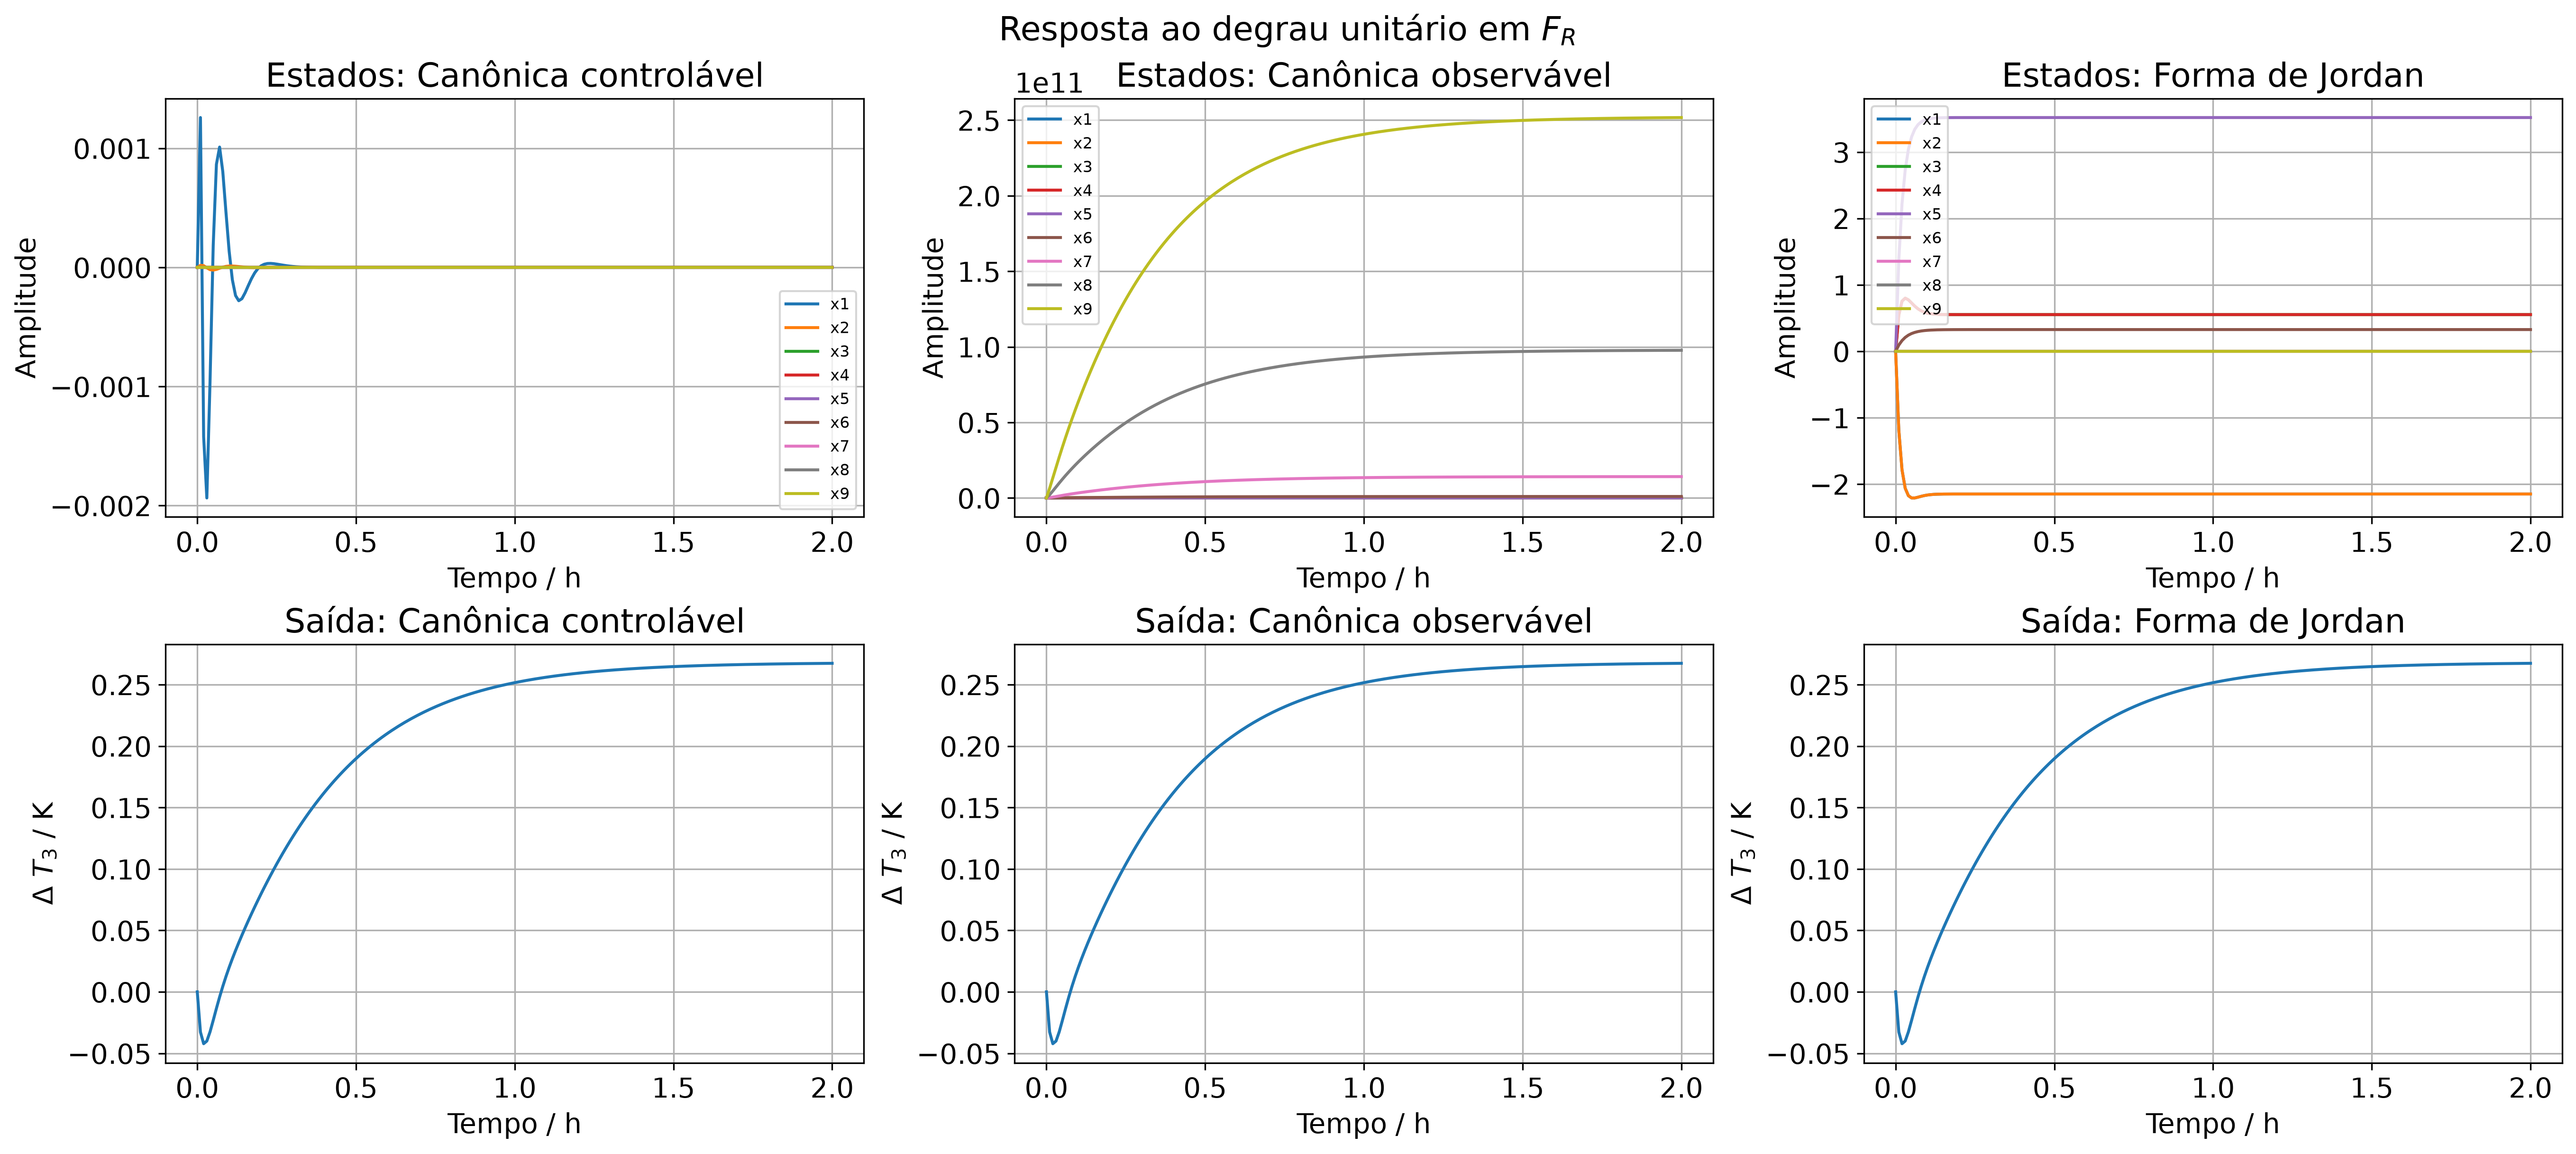

In [5]:
from lib.plots import plot_and_show, plt
from lib.utils import input_labels, output_labels, output_units

# Sistemas a simular
sistemas = [
    ("Canônica controlável", Ac, Bc, Cc, Dc),
    ("Canônica observável", Ao, Bo, Co, Do),
    ("Forma de Jordan", A_J, B_J, C_J, D_J),
]

# Degrau unitário na entrada escolhida (i, j vêm de ij)
tt = np.linspace(0, 2, 200)
u = np.ones_like(tt)

# O modelo está em variáveis de desvio, então a saída é um desvio
ylabel_saida = rf"$\Delta$ {output_labels[i]} / {output_units[i]}"

fig, axes = plt.subplots(2, 3, figsize=(18, 8), constrained_layout=True)
fig.suptitle(f"Resposta ao degrau unitário em {input_labels[j]}")

for c, (nome, A, B, C, D) in enumerate(sistemas):
    sys = signal.StateSpace(A, B, C, D)

    # Simulação da resposta ao degrau
    tout, yout, xout = signal.lsim(sys, U=u, T=tt)

    # Linha superior: estados (sem unidade física)
    for k in range(xout.shape[1]):
        axes[0, c].plot(tout, np.real(xout[:, k]), label=f"x{k + 1}")

    axes[0, c].set_title(f"Estados: {nome}")
    axes[0, c].set_ylabel("Amplitude")
    axes[0, c].legend(fontsize=8)
    axes[0, c].set_xlabel("Tempo / h")

    # Linha inferior: saída
    axes[1, c].plot(tout, np.real(np.squeeze(yout)))
    axes[1, c].set_title(f"Saída: {nome}")
    axes[1, c].set_ylabel(ylabel_saida)
    axes[1, c].set_xlabel("Tempo / h")

plot_and_show(f"formas_canonicas-{output_names[i]}_{input_names[j]}")
